<a href="https://colab.research.google.com/github/kshamasahu706-wq/Customer-Churn-Feature-Engineering/blob/main/Feature_Engineering_Preprocessing_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Feature Engineering & Preprocessing Pipeline

**Objective:** Build a robust, reusable and leak-free Scikit-Learn preprocessing pipeline that performs missing-value imputation, numerical scaling, categorical one-hot encoding, correlation analysis, and tree-based feature importance.

### Key design principle
The train/test split is performed **before fitting any preprocessing step**. All imputers, scalers and encoders are fitted only on the training data through Scikit-Learn pipelines, preventing data leakage.


## 1. Import Libraries

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



## 2. Load a Complex Tabular Dataset

We use the **Ames Housing** dataset from OpenML. It contains numerical and categorical variables and is suitable for demonstrating preprocessing and feature engineering.

The target variable is `SalePrice`.


In [ ]:

# Load the Ames Housing dataset
ames = fetch_openml(name="house_prices", as_frame=True)

X = ames.data.copy()
y = pd.to_numeric(ames.target, errors="coerce")

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
X.head()


Dataset shape: (1460, 80)
Target shape: (1460,)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal


## 3. Basic Dataset Inspection

In [ ]:

print("Data types:")
display(X.dtypes.value_counts())

print("\nMissing values - top 20 columns:")
display(X.isna().sum().sort_values(ascending=False).head(20))

print("\nTarget statistics:")
display(y.describe())


Data types:


,count
object,43
int64,34
float64,3



Missing values - top 20 columns:


,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageQual,81
GarageFinish,81



Target statistics:


,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000



## 4. Train/Test Split — Before Preprocessing

This is an essential leakage-prevention step. We split the raw data first. The preprocessing pipelines below are then fitted only on `X_train`.


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)


Training set: (1168, 80)
Testing set : (292, 80)


## 5. Identify Numerical and Categorical Features

In [ ]:

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nSample numerical features:", numeric_features[:10])
print("Sample categorical features:", categorical_features[:10])


Number of numerical features: 37
Number of categorical features: 43

Sample numerical features: ['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1']
Sample categorical features: ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1']



## 6. Build Numerical and Categorical Pipelines

### Numerical pipeline
- Median imputation handles missing numerical values.
- `StandardScaler` puts numerical features on a comparable scale.

### Categorical pipeline
- Most-frequent imputation handles missing categories.
- `OneHotEncoder` converts categorical variables into numerical indicator columns.

Because these operations are inside pipelines, their parameters are learned only from the training data when the complete model pipeline is fitted.


In [ ]:

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessor created successfully.")


Preprocessor created successfully.



## 7. Create the Complete Reusable Machine Learning Pipeline

A Random Forest Regressor is used for prediction and feature-importance analysis. The preprocessing and model are kept together in one reusable Scikit-Learn pipeline.


In [ ]:

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", model)
])

# Fit ONLY on training data
pipeline.fit(X_train, y_train)

print("Pipeline fitted successfully.")


Pipeline fitted successfully.


## 8. Evaluate the Model

In [ ]:

y_pred = pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")


Mean Absolute Error (MAE): 17,491.53
Root Mean Squared Error (RMSE): 28,361.32
R² Score: 0.8951



## 9. Correlation Analysis

Correlation analysis is performed on the numerical part of the training data. This is descriptive analysis and is kept separate from the predictive preprocessing pipeline.


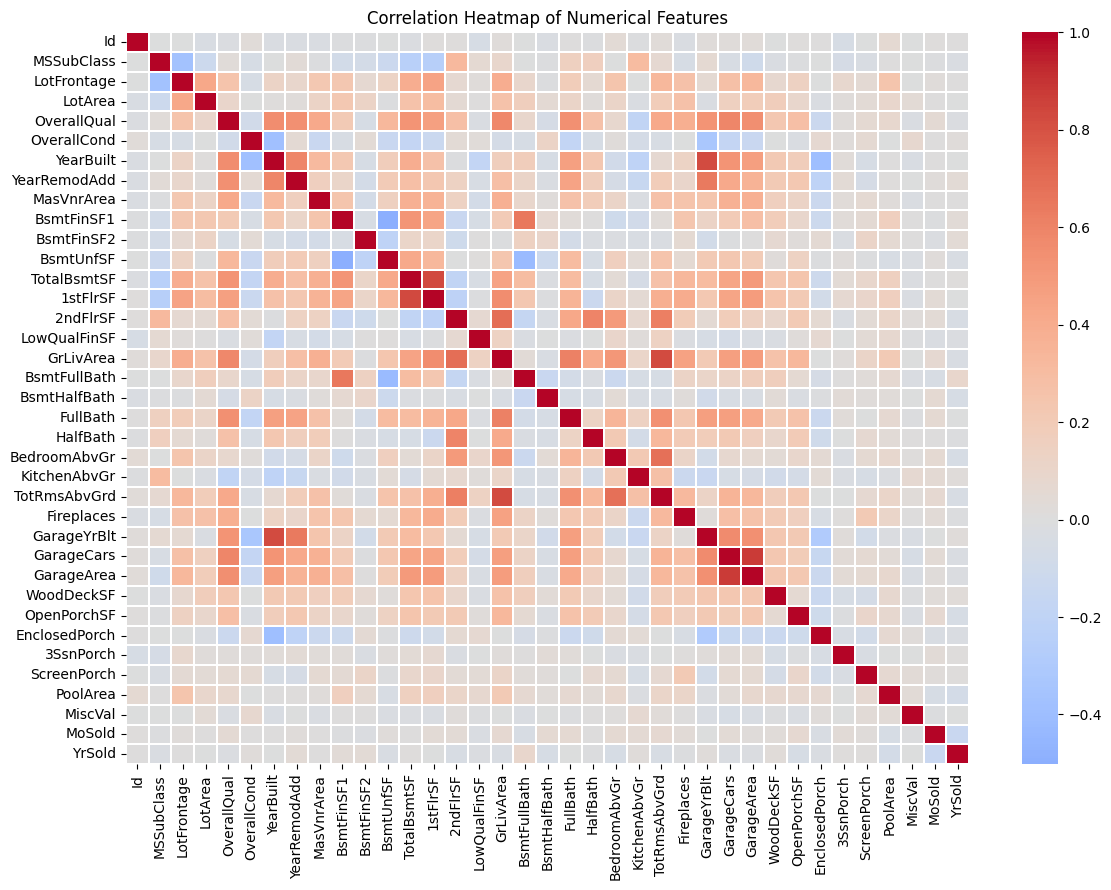

In [ ]:

numeric_train = X_train.select_dtypes(include=["number"]).copy()
correlation = numeric_train.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

# Show strongest correlations with SalePrice where available
if "SalePrice" in numeric_train.columns:
    corr_with_target = correlation["SalePrice"].abs().sort_values(ascending=False)
    print("Strongest numerical correlations with SalePrice:")
    display(corr_with_target.head(15))



## 10. Extract Transformed Feature Names

After fitting, we can inspect the feature names generated by the `ColumnTransformer`, including one-hot encoded categorical features.


In [ ]:

fitted_preprocessor = pipeline.named_steps["preprocessor"]

feature_names = fitted_preprocessor.get_feature_names_out()

print("Number of transformed features:", len(feature_names))
print("\nFirst 30 transformed features:")
display(pd.Series(feature_names[:30], name="feature"))


Number of transformed features: 287

First 30 transformed features:


,feature
0,num__Id
1,num__MSSubClass
2,num__LotFrontage
3,num__LotArea
4,num__OverallQual
5,num__OverallCond
6,num__YearBuilt
7,num__YearRemodAdd
8,num__MasVnrArea
9,num__BsmtFinSF1



## 11. Tree-Based Feature Importance

Random Forest provides an importance value for each transformed feature. This allows us to identify which original/encoded features contributed most to the model's predictions.

**Important:** Feature importance indicates model association/usefulness, not causation.


In [ ]:

rf_model = pipeline.named_steps["model"]
importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

display(importance_df.head(20))


,feature,importance
4,num__OverallQual,0.554349
16,num__GrLivArea,0.122021
12,num__TotalBsmtSF,0.033696
14,num__2ndFlrSF,0.031462
13,num__1stFlrSF,0.026852
9,num__BsmtFinSF1,0.026658
3,num__LotArea,0.017572
27,num__GarageArea,0.015324
26,num__GarageCars,0.013804
6,num__YearBuilt,0.012078


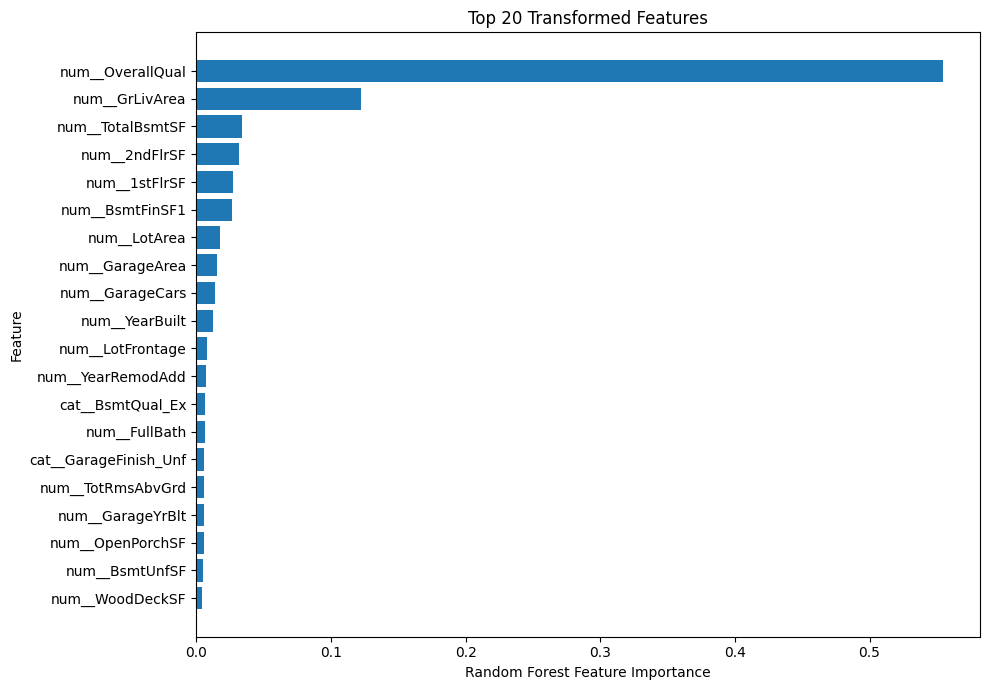

In [ ]:

top_n = 20
top_features = importance_df.head(top_n).sort_values("importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Random Forest Feature Importance")
plt.ylabel("Feature")
plt.title(f"Top {top_n} Transformed Features")
plt.tight_layout()
plt.show()



## 12. Verify the Preprocessing Output

This confirms that missing-value imputation, scaling and one-hot encoding can be applied consistently to both training and unseen test data through the same fitted pipeline.


In [ ]:

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

print("Transformed training shape:", X_train_transformed.shape)
print("Transformed testing shape :", X_test_transformed.shape)


Transformed training shape: (1168, 287)
Transformed testing shape : (292, 287)



## 13. Why This Pipeline Is Leak-Free

1. The raw dataset is split into training and testing sets first.
2. The numerical imputer learns its median values only from `X_train`.
3. The scaler learns its mean and standard deviation only from `X_train`.
4. The categorical imputer learns category frequencies only from `X_train`.
5. The One-Hot Encoder is fitted only on `X_train`; `handle_unknown="ignore"` safely handles unseen test categories.
6. The Random Forest is fitted only after the preprocessing pipeline is fitted on training data.
7. The test set is used only for final evaluation.

Therefore, information from the test set is not used to learn preprocessing parameters.



## 14. Save the Trained Pipeline for Reuse

The complete pipeline can be saved and later loaded for predictions on new data.


In [ ]:

import joblib

joblib.dump(pipeline, "feature_engineering_preprocessing_pipeline.joblib")
print("Saved: feature_engineering_preprocessing_pipeline.joblib")


Saved: feature_engineering_preprocessing_pipeline.joblib



## 15. Final Conclusion

This notebook implements a reusable Scikit-Learn preprocessing pipeline for a mixed-type tabular dataset. It performs missing-value imputation, numerical scaling, categorical one-hot encoding, correlation analysis, and tree-based feature importance. The train/test split is performed before preprocessing, and all learnable preprocessing operations are contained inside the Scikit-Learn pipeline, making the workflow resistant to data leakage and suitable for reuse on unseen data.
